### Configuration 

In [ ]:
import mne
import numpy as np
import pandas as pd
import scipy.integrate as integrate
import matplotlib.pyplot as plt
%matplotlib qt

# Base Status (Rest)
BASE_EDF_PATH = "ensemble_de_donnees/nouveau_test_weihao/rest/Weihao rest_EPOCX_812190_2026.09.10T16.27.57+08.00.edf"

# Target: Chocolate
TASK_EDF_PATH = "ensemble_de_donnees/nouveau_test_weihao/chocolat/Weihao mange chocolat_EPOCX_812190_2026.09.10T16.43.55+08.00.edf"
TASK_CSV_PATH = "ensemble_de_donnees/nouveau_test_weihao/chocolat/Weihao mange chocolat_EPOCX_812190_2026.09.10T16.43.55+08.00_intervalMarker.csv"

# EEG Headset Configuration
EEG_CHANNELS = [
    "AF3", "F7", "F3", "FC5", "T7", "P7", "O1",
    "O2", "P8", "T8", "FC6", "F4", "F8", "AF4" 
]

# Channels for Engagement Index Calculation
EI_CHANNELS = ["AF3", "AF4", "F3", "F4", "FC5", "FC6"]

# Adjustment on Time Markers
KEYSTROKE_OFFSET_S = 2.0   # Shift markers 2.0s earlier
SWALLOW_WINDOW_S = 5.0     # 5.0s duration for Swallow phase
POST_SWALLOW_WIN_S = 30.0  # 30.0s window for Post-Swallow time series

# Power Bands
POWER_BANDS = {
    "Theta": (4.0, 8.0),
    "Alpha": (8.0, 13.0),
    "Beta": (13.0, 30.0)
}

Channels marked as bad:
none
Channels marked as bad:
none
Channels marked as bad:
none
Channels marked as bad:
none
Channels marked as bad:
none
Channels marked as bad:
none
Channels marked as bad:
none


### Read File

In [6]:
def load_edf_file(edf_path, verbose_on=True):
    raw_eeg = mne.io.read_raw_edf(edf_path, preload=True, verbose=verbose_on)

    rename_map = { ch: ch.replace("EEG.", "").strip() for ch in raw_eeg.ch_names }
    raw_eeg.rename_channels(rename_map)
    raw_eeg.pick(EEG_CHANNELS)

    # Scale by 1e-6 if values are recorded in uV instead of Volts
    data_ptp = np.ptp(raw_eeg.get_data())
    if data_ptp > 0.1:
        print("Transforming microvolts to volts...")
        raw_eeg.apply_function(lambda x: x * 1e-6, picks="eeg")

    montage = mne.channels.make_standard_montage("standard_1020")
    raw_eeg.set_montage(montage, on_missing="ignore")

    return raw_eeg

In [16]:
base_eeg = load_edf_file(BASE_EDF_PATH)
task_eeg = load_edf_file(TASK_EDF_PATH)

Extracting EDF parameters from ensemble_de_donnees/nouveau_test_weihao/rest/Weihao rest_EPOCX_812190_2026.09.10T16.27.57+08.00.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 15487  =      0.000 ...   120.992 secs...
Extracting EDF parameters from ensemble_de_donnees/nouveau_test_weihao/chocolat/Weihao mange chocolat_EPOCX_812190_2026.09.10T16.43.55+08.00.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 53119  =      0.000 ...   414.992 secs...


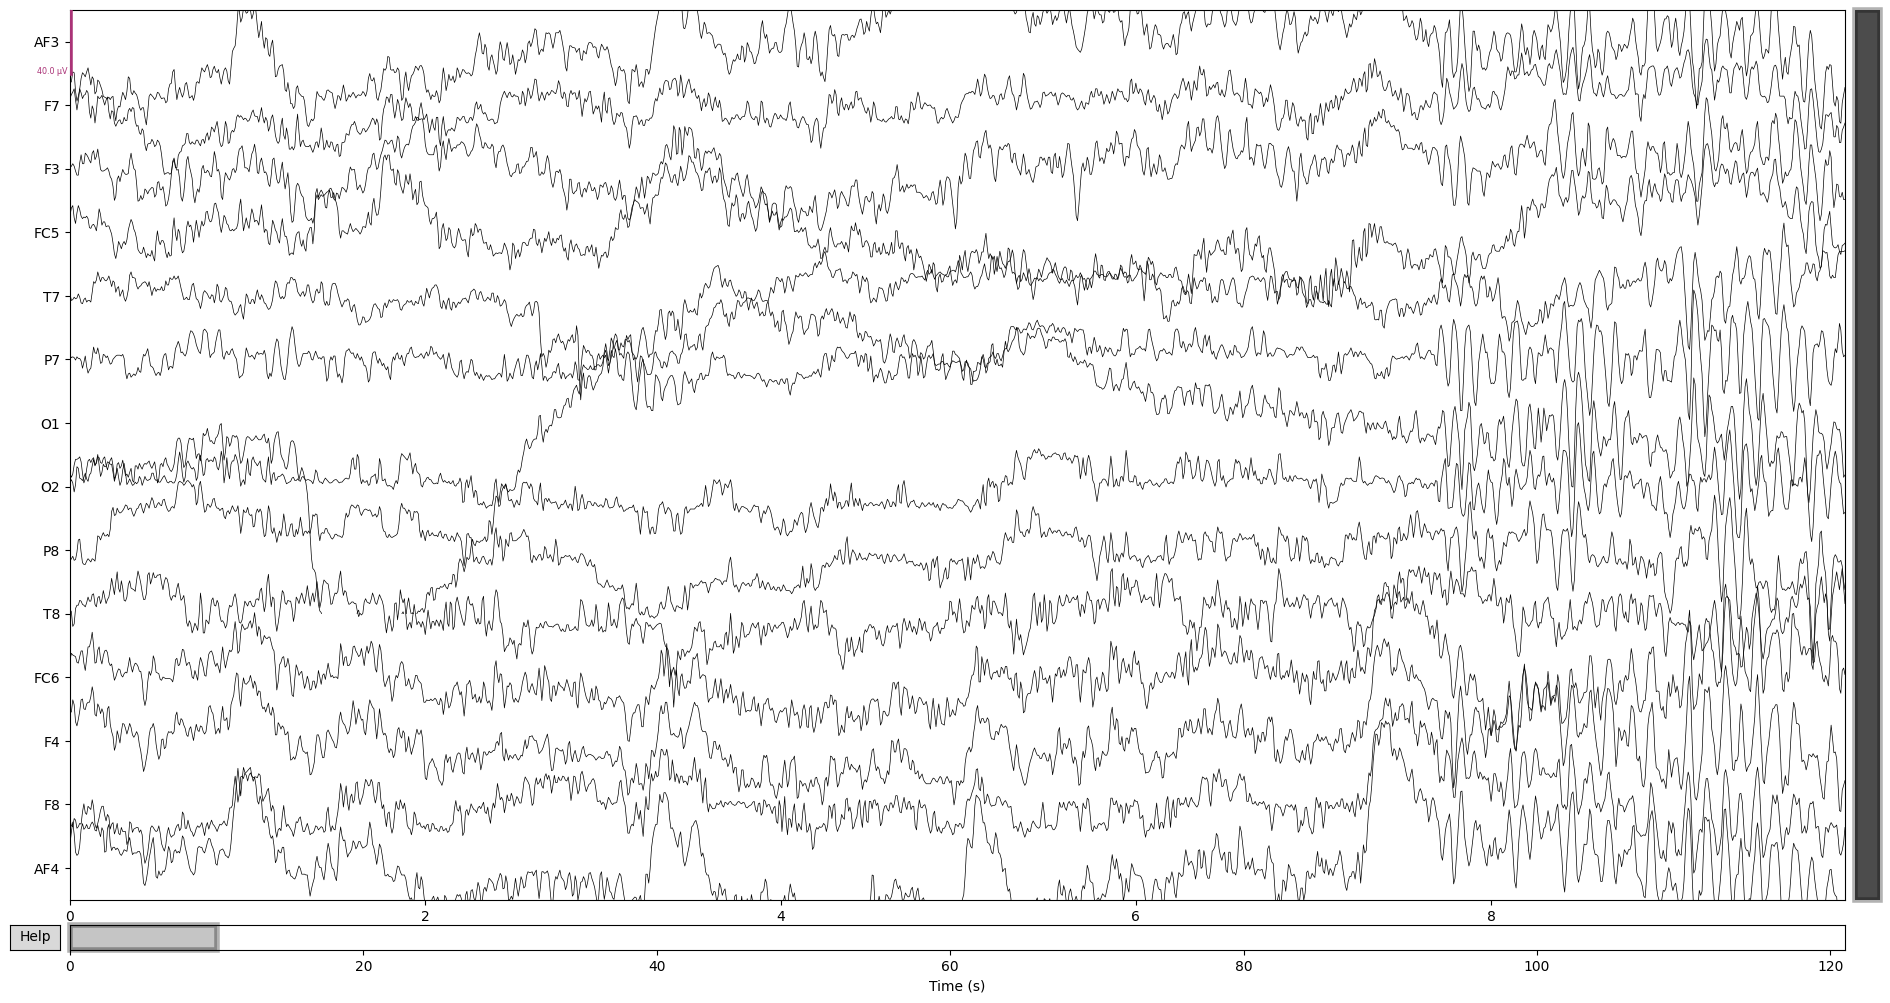

In [17]:
base_eeg.plot()

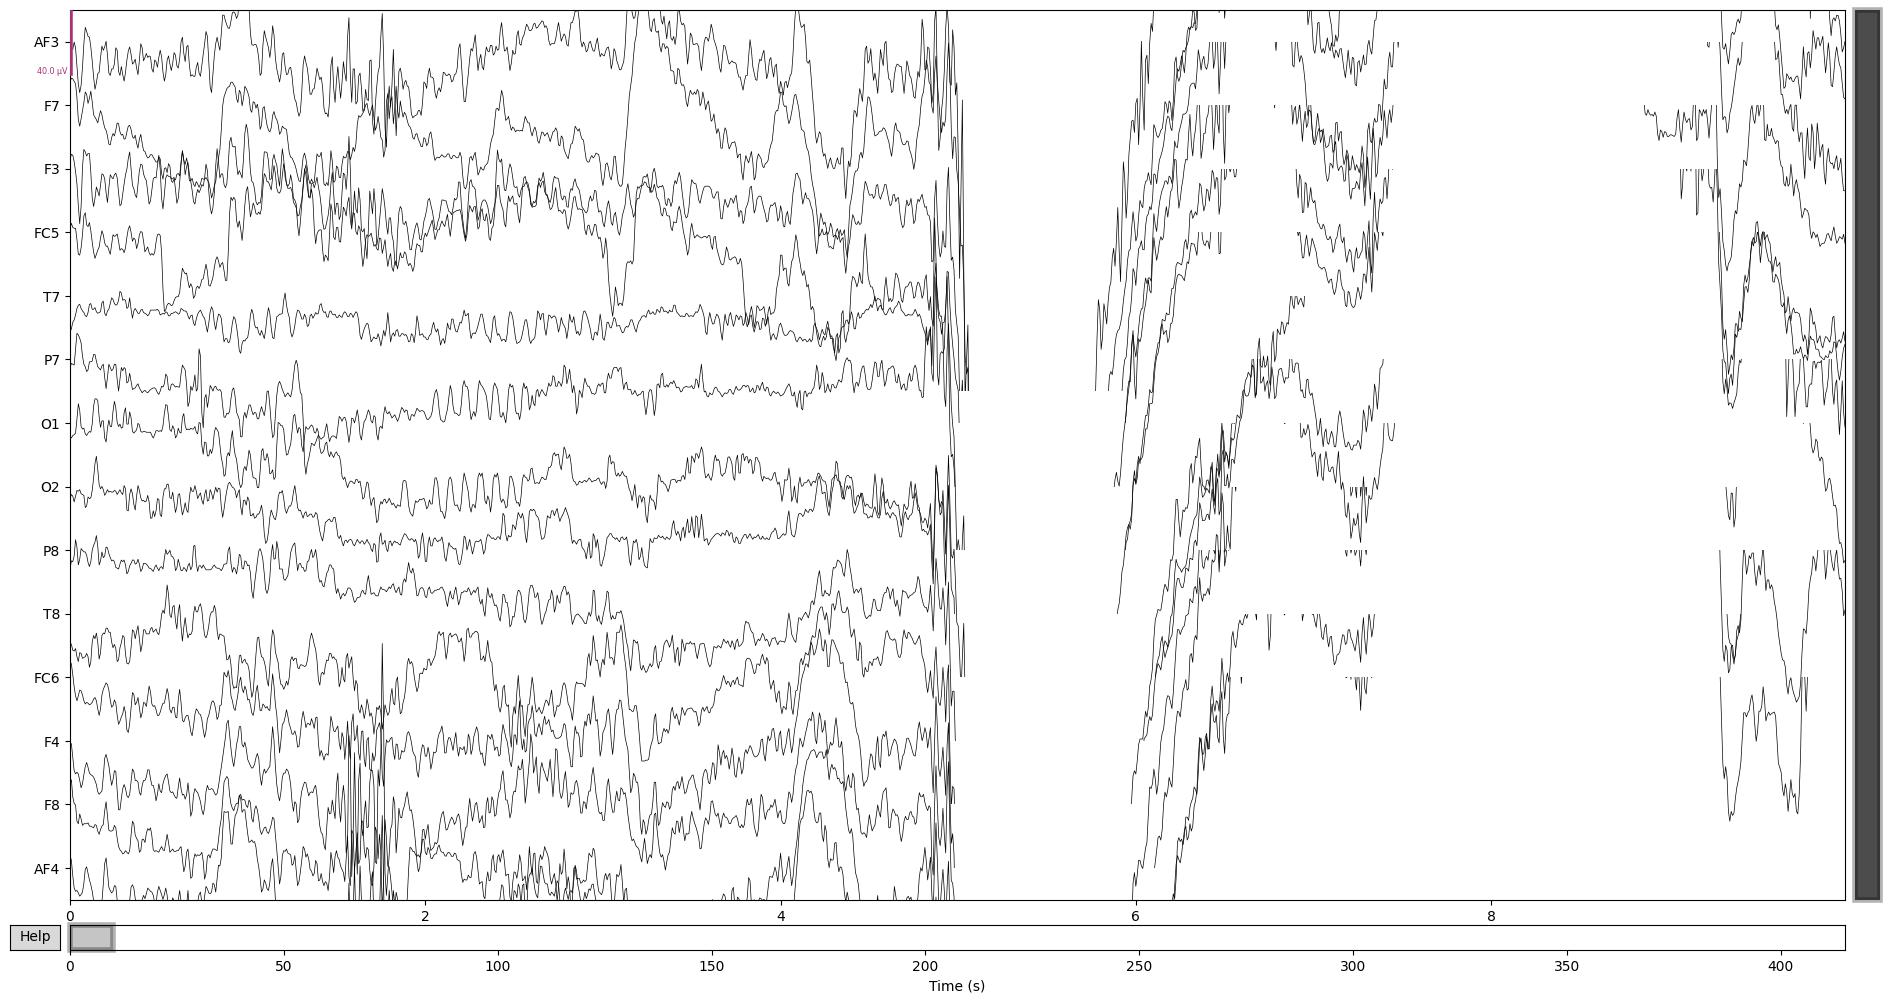

In [18]:
task_eeg.plot()

### Preprocessing

In [9]:
def filter_ica_eeg(eeg_input, l_freq=1.0, h_freq=40.0, verbose_on=True):
    # Bandpass filter (1 - 40 Hz) with zero-phase FIR filter
    eeg_input.filter(l_freq=l_freq, h_freq=h_freq, fir_design="firwin", verbose=verbose_on)

    # ICA for ocular and EMG artefact removal
    ica = mne.preprocessing.ICA(
        n_components=len(EEG_CHANNELS),
        random_state=42,
        max_iter="auto"
    )
    ica.fit(eeg_input, verbose=verbose_on)

    bad_ica_comps = []
    # Detect eye blinks at frontal channels
    eog_indices, eog_scores = ica.find_bads_eog(eeg_input, ch_name=["AF3", "AF4"], threshold=2.5, verbose=verbose_on)
    bad_ica_comps.extend(eog_indices)

    # Detect high-frequency muscular components
    try:
        muscle_indices, muscle_scores = ica.find_bads_muscle(eeg_input, threshold=0.6, verbose=verbose_on)
        bad_ica_comps.extend(muscle_indices)
    except Exception:
        pass

    ica.exclude = list(set(bad_ica_comps))
    print(f"Excluded ICA components: {ica.exclude}")

    return ica.apply(eeg_input.copy(), verbose=verbose_on)

In [ ]:
clean_base_eeg = filter_ica_eeg(base_eeg)
clean_task_eeg = filter_ica_eeg(task_eeg)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 423 samples (3.305 s)

Fitting ICA to data using 14 channels (please be patient, this may take a while)
Selecting by number: 14 components
Fitting ICA took 0.2s.
Using EOG channels: AF3, AF4
... filtering ICA sources
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower p

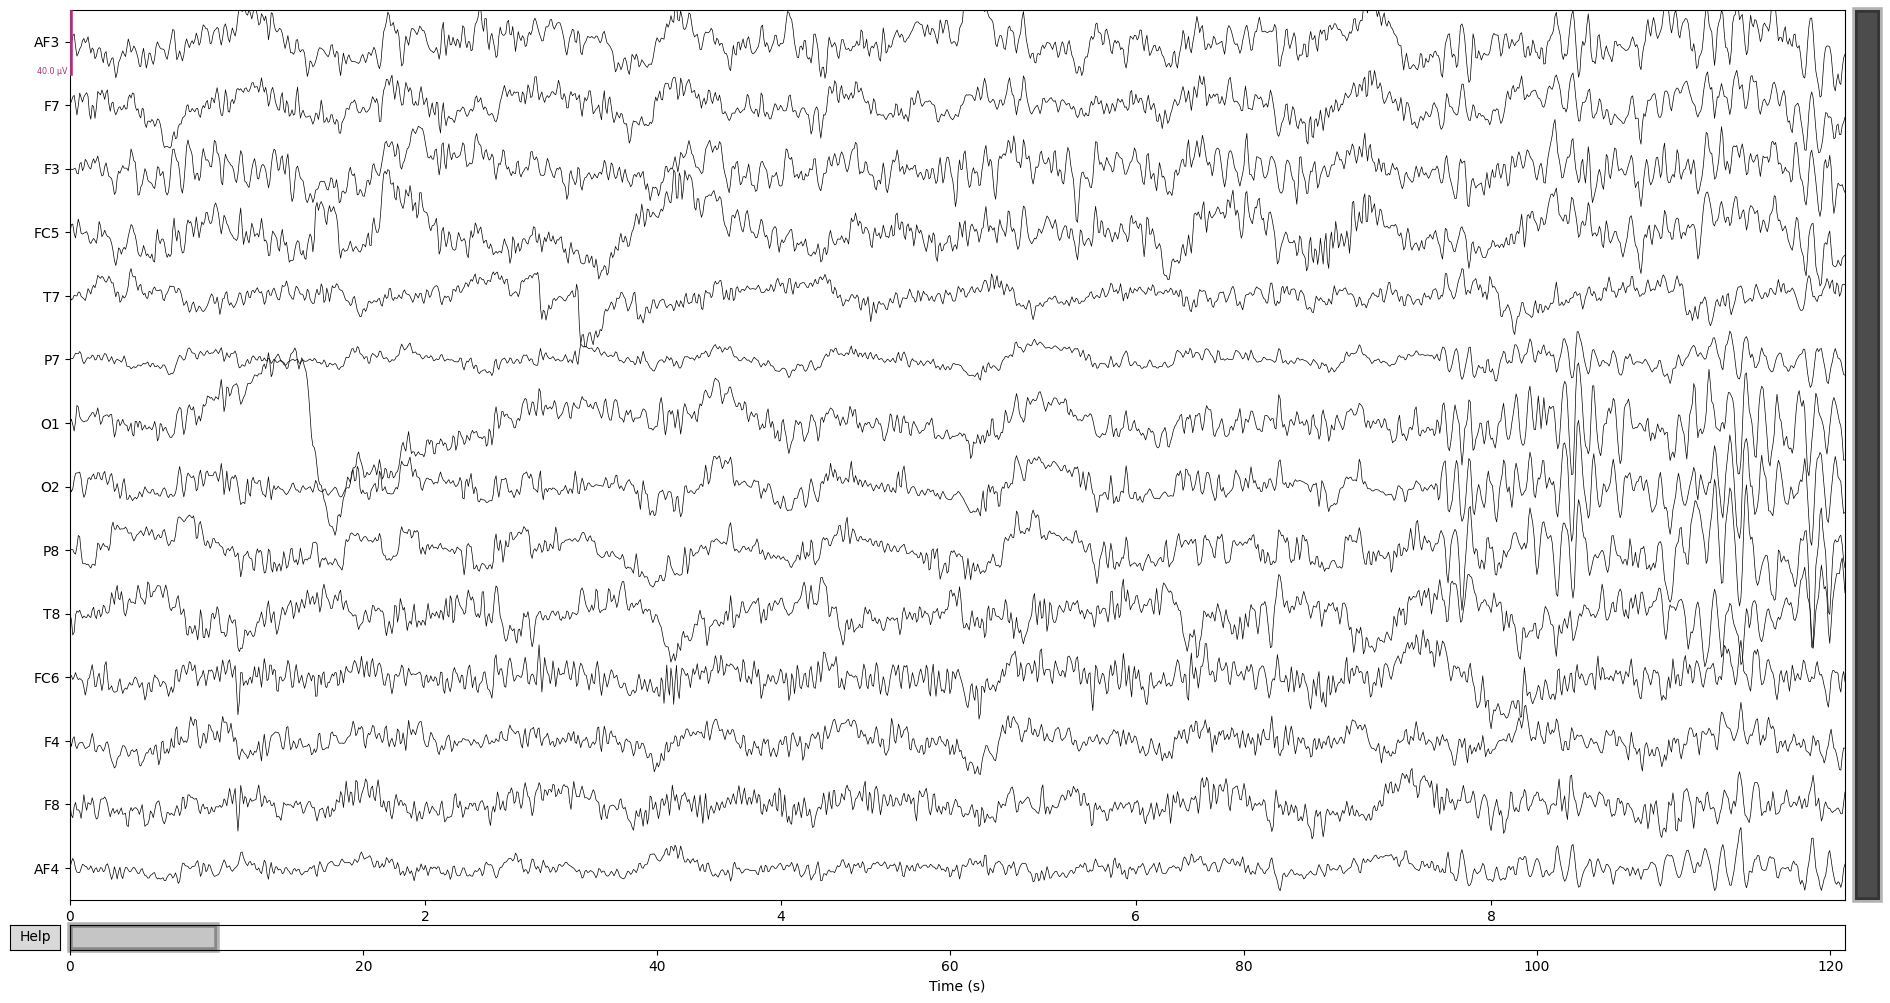

In [15]:
clean_base_eeg.plot()

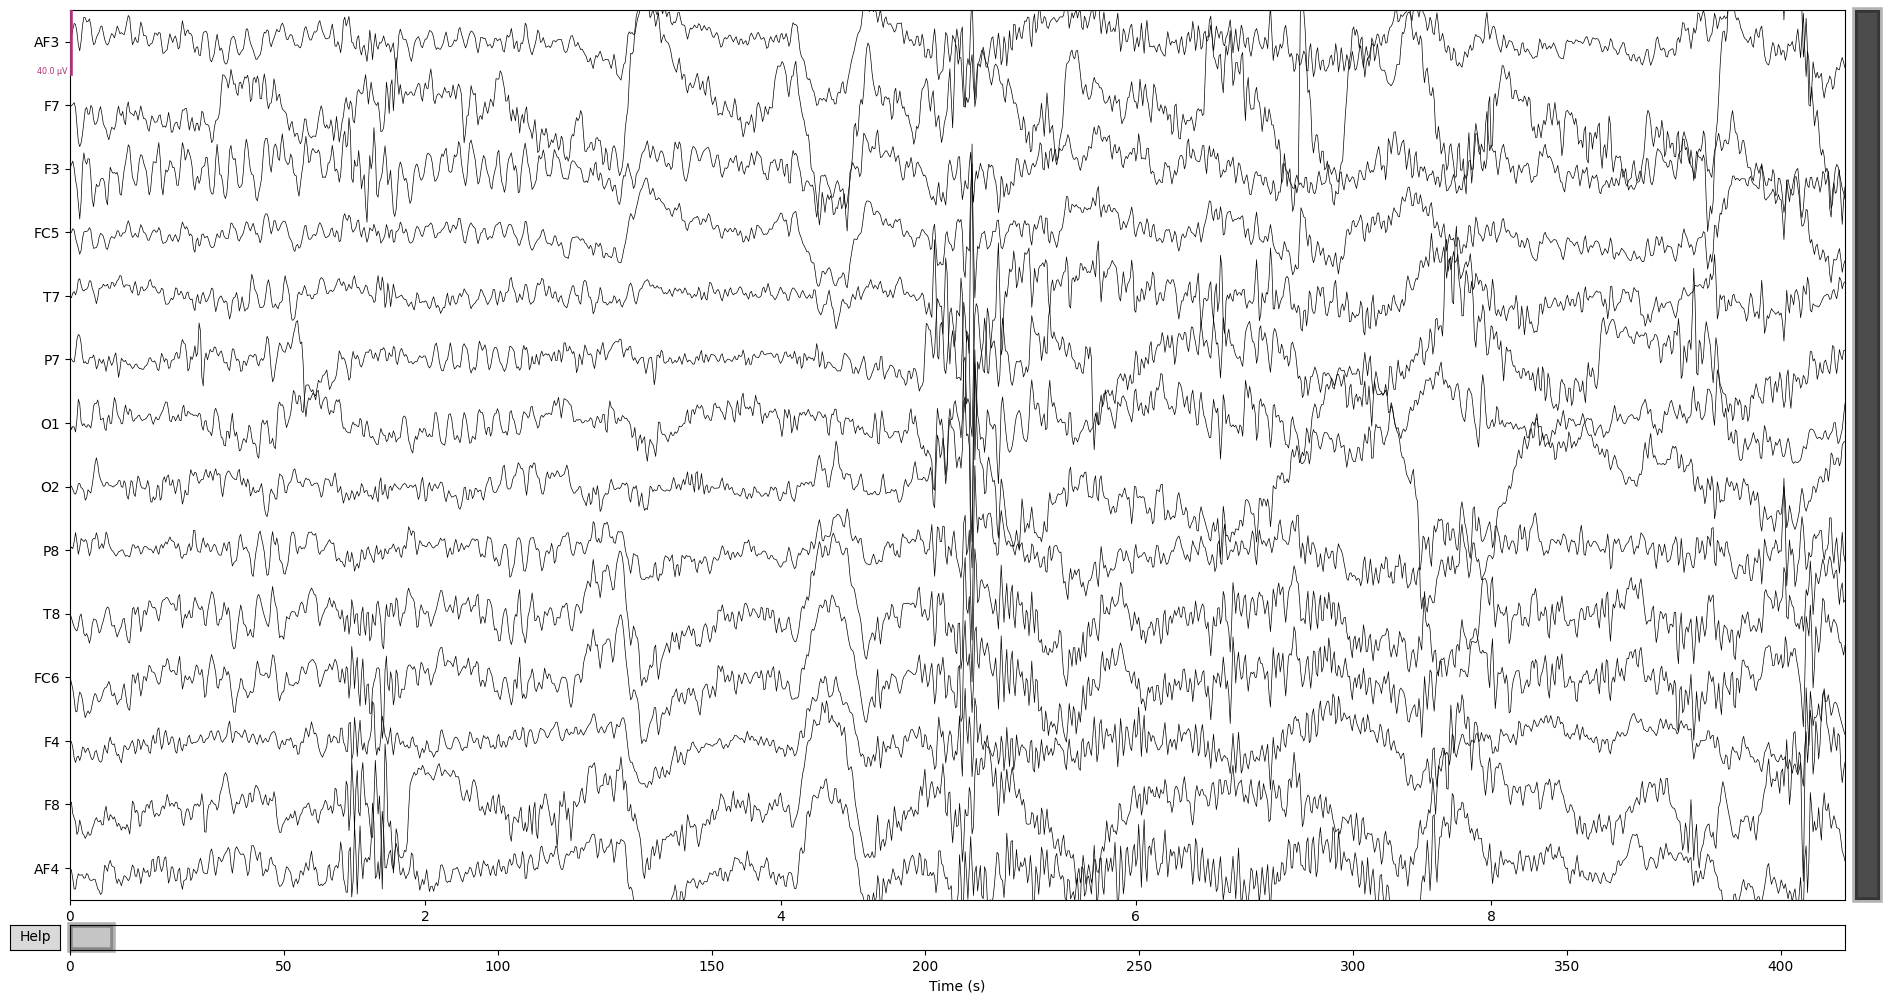

In [14]:
clean_task_eeg.plot()